# Complete Locking Acquisition for the Virgo Model

In this notebook we will lock the ideal (no defects) Virgo interferometer following the lock acquisition of the actual experiment. 

In [1]:
import finesse
from finesse import Model
from finesse.analysis.actions import (
    Change,
    Maximize,
    Minimize,
    Series,
    SensingMatrixDC,
    OptimiseRFReadoutPhaseDC,
    SetLockGains,
    GetErrorSignals,
    RunLocks,
)

import matplotlib.pyplot as plt

from ifotools.finesse import model_info, plotting
from ifotools.virgo import model_info as model_info_virgo

finesse.init_plotting()

## 1. Initialising AdV O4 Model

Now we will build/initialise the model using custom katscripts. Then we will follow the steps to bring the interferometer to the DC readout lock: 

1. Bringing the arms to resonance for the IR
2. Creating a known CARM-offset to bring the IR out of resonance for the arm cavities
3. Locking the CITF: MICH, PRCL, and SRCL dofs
4. CARM-offset reduction
5. Locking CARM and DARM dof and steady state lock of all the dofs
6. DC readout lock

In [2]:
# Advanced Virgo model
dir = "../virgokatfiles"
advi = Model()

# Optical model of Virgo
advi.parse_file(f"{dir}/Virgo_LMA.kat")
advi.parse_file(f"{dir}/cavities.kat")
advi.parse_file(f"{dir}/variables.kat")

# readouts and detectors
advi.parse_file(f"{dir}/dofs.kat")
advi.parse_file(f"{dir}/readouts.kat")
advi.parse_file(f"{dir}/detectors_rf.kat")
advi.modes(maxtem=4)

# Printing model state
model_info_virgo.print_model_state(advi, verbose=True) #check
model_info_virgo.print_lengths_frequencies(advi)

DOFs          Locks         Readouts      Cavities      Mechanics     Etalon State    Phase Config    HOMs          
Yes           No            Yes           Yes           No            Linked          Phase 2         Yes           
┌──────────────┬────────┬──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┐
│ Item         │ Count  │ Details                                                                                                                                                                                                      │
╞══════════════╪════════╪══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════╡
│ DOFs         │ (11/5) │ MICH, DARM, CARM, PRCL, SRCL, NE_z, NI_z,

## 2. Adjusting Lengths and RoCs (TCS)

Optimization of the lengths and rocs based on characterization, and tcs settings. 

In [3]:
advi_length = advi.deepcopy()
# # pretuning schnupp asymmetry to 0.23
# pretuning.adjust_variable_length(
#     advi_length,
#     variable="lSchnupp",
#     space_to_change="lBS_CPN",
#     target_length=0.23,
#     verbose=False,
# )

# # pretuning PRC length to 11.952 m by adjusting lPOP_BS
# pretuning.adjust_variable_length(
#     advi_length,
#     variable="lPRC",
#     space_to_change="lPOP_BS",
#     target_length=11.952,
#     verbose=False,
# )

# # pretuning PRC length to 11.952 m by adjusting lPOP_BS
# pretuning.adjust_variable_length(
#     advi_length,
#     variable="lSRC",
#     space_to_change="lsr",
#     target_length=11.952,
#     verbose=False,
# );

## Add RoC changes once the function has been pushed # check
advi_length.rocPR = -1430
advi_length.rocSR = 1430

## 3. Local Control of the arms and CARM-offset

Here we locally control the North and West end mirror to bring the arm cavities to resonance for the IR (main laser). The CARM and DARM dofs are not used at this stage of the lock acquisition.

Steps:
1. We misalign the recycling mirrors (PRM and SRM) except for the arms that we want to maximize. 

2. After the misalignment we maximize the power transmitted while using the individual (end mirrors) dof. 

3. After bringing the arm cavities in resonance for the IR, we create a known offset called the CARM-offset to bring the IR out of resonance in the arm cavities. At this point the arm cavities are controlled by the green laser (ALS).

In [4]:
armsIR = advi_length.deepcopy()

# Misaligning the optics/mirrors and keeping just the arm cavities
armsIR.run(
    Change(
        {
            "PR.misaligned": True,
            "SR.misaligned": True,
            "eom8.midx": 0,
        }
    )
)

# pre-tuning: Maximizing the powers for the IR 
armsIR.run(
    Series(
        Maximize("B7_DC", "NE_z.DC", bounds=[-180, 180], tol=1e-14),
        Maximize("B8_DC", "WE_z.DC", bounds=[-180, 180], tol=1e-14),
    )
);

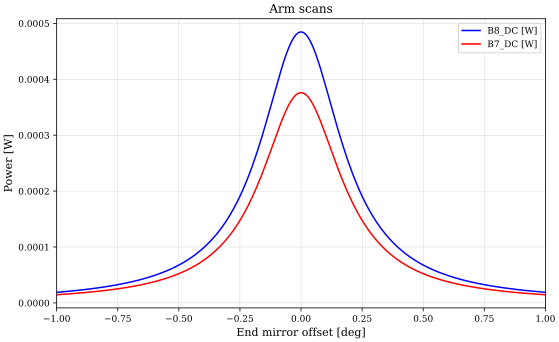

In [5]:
# The scan is relative to each dof's current DC value (the pre-tuned point).
fig, ax = plt.subplots(figsize=(8, 5))
plotting.plot_dof_scan(armsIR, "WE_z", "B8_DC", (-1, 1, 200), logy=False, ax=ax)
plotting.plot_dof_scan(armsIR, "NE_z", "B7_DC", (-1, 1, 200), logy=False, ax=ax)
ax.set(title="Arm scans", xlabel="End mirror offset [deg]", ylabel="Power [W]")
plt.tight_layout()
plt.show()

In [6]:
# Checking the tunings after the pre-tuning
# of the arm cavities. Only the dofs are printed here
model_info.print_tunings(armsIR, only_dof=True)

┌───────╥──────────────┬─────────────┬───────────┬────────────────────────────────────────┐
│ optic ║ tuning [deg] │ tuning [nm] │ phi [deg] │ Symbolic                               │
╞═══════╬══════════════╪═════════════╪═══════════╪════════════════════════════════════════╡
│ NI    ║            0 │           0 │         0 │ -MICH.DC + NI_z.DC                     │
│ WE    ║    2.783e-06 │   8.224e-06 │         0 │ CARM.DC + DARM.DC + MICH.DC + WE_z.DC  │
│ NE    ║    2.103e-06 │   6.217e-06 │         0 │ -DARM.DC - MICH.DC + CARM.DC + NE_z.DC │
│ SR    ║            0 │           0 │         0 │ -SRCL.DC + SR_z.DC                     │
│ PR    ║            0 │           0 │         0 │ PRCL.DC + PR_z.DC                      │
│ WI    ║            0 │           0 │         0 │ MICH.DC + WI_z.DC                      │
└───────╨──────────────┴─────────────┴───────────┴────────────────────────────────────────┘



In [7]:
model_info_virgo.print_powers(armsIR)
# check/add my function of dcpowers to the print

┌─────────────┬─────────┬───────────────┬─────────────┐
│ Location    │ Node    │ Carrier power │ Total power │
╞═════════════╪═════════╪═══════════════╪═════════════╡
│ North arm   │ NE.p1.o │ 110.98 W      │ 110.98 W    │
│ West arm    │ WE.p1.o │ 110.2 W       │ 110.2 W     │
│ PRC         │ BS.p1.i │ 777.1 mW      │ 820.96 mW   │
│ Dark fringe │ B1.p1.i │ --            │ --          │
└─────────────┴─────────┴───────────────┴─────────────┘



In [8]:
# model_info_virgo.print_readout_powers(armsIR) #check

### CARM-offset

In [9]:
## Aligning back the arms and creating a known offset (1.5 kHz per arm)
## This automatically puts the IR beam out of resonance in the arm cavities
## and also the PRC
carm_offset = armsIR.deepcopy()
# Aligning back the North arm which was misaligned
carm_offset.run(
    Change({"NI.misaligned": False, "NIAR.misaligned": False, "NE.misaligned": False})
)

run0 = carm_offset.run()

## Adding the CARM offset to the end mirrors
## We don't disturb the CARM & DARM tunings here.
## We simply control the individual mirror dofs.
carm_offset.NE_z.DC += 10.8
carm_offset.WE_z.DC += 10.8

model_info.print_tunings(carm_offset, only_dof=True)

┌───────╥──────────────┬─────────────┬───────────┬────────────────────────────────────────┐
│ optic ║ tuning [deg] │ tuning [nm] │ phi [deg] │ Symbolic                               │
╞═══════╬══════════════╪═════════════╪═══════════╪════════════════════════════════════════╡
│ NI    ║            0 │           0 │         0 │ -MICH.DC + NI_z.DC                     │
│ SR    ║            0 │           0 │         0 │ -SRCL.DC + SR_z.DC                     │
│ WI    ║            0 │           0 │         0 │ MICH.DC + WI_z.DC                      │
│ WE    ║         10.8 │       31.92 │         0 │ CARM.DC + DARM.DC + MICH.DC + WE_z.DC  │
│ NE    ║         10.8 │       31.92 │         0 │ -DARM.DC - MICH.DC + CARM.DC + NE_z.DC │
│ PR    ║            0 │           0 │         0 │ PRCL.DC + PR_z.DC                      │
└───────╨──────────────┴─────────────┴───────────┴────────────────────────────────────────┘



## 4. CITF control of the interferometer

Now once this CARM-offset is completed, we have disentangled the CITF longitudinal dofs with the CARM and DARM dof. This makes the lock acquisition of the CITF easier. 

Steps to lock the CITF:
1. Pre-tuning the CITF to bring it to the right working point or close by.
2. Check figures of merits and error signals of the pre-tuning sequence.  
3. Locking the CITF dofs first using 1f signals and later using 3f to check if both the error signals work. 

In [10]:
# Building a new model for the CITF with the carm offset
citf = carm_offset.deepcopy()

# Bringing the PR and SR mirrors to aligned
# At this point all the mirrors are aligned with the arms having
# a CARM-offset.
citf.run(Change({"PR.misaligned": False, "SR.misaligned": False}));

In [11]:
# model_info_virgo.print_readout_powers(citf)

In [12]:
# Pretuning to bring the CITF dofs to the working point
citf_wp = citf.deepcopy()

# adding amplitude detectors for the pretuning sequence
citf_wp.parse(
    """
    ad b1padc SRAR.p2.o f=l1.f n=0 m=0
    """
)

# Pre-tuning the CITF dofs to the working point
citf_wp.run(
    Series(
        Minimize("b1padc", "MICH.DC", bounds=[-180, 180], tol=1e-10),
        Maximize("b4_12", "PRCL.DC", bounds=[-180, 180], tol=1e-10),
        Maximize("b4_112", "SRCL.DC", bounds=[-180, 180], tol=1e-10),
    )
);

In [13]:
model_info.print_tunings(citf_wp, only_dof=True)

┌───────╥──────────────┬─────────────┬───────────┬────────────────────────────────────────┐
│ optic ║ tuning [deg] │ tuning [nm] │ phi [deg] │ Symbolic                               │
╞═══════╬══════════════╪═════════════╪═══════════╪════════════════════════════════════════╡
│ WE    ║         10.8 │       31.91 │         0 │ CARM.DC + DARM.DC + MICH.DC + WE_z.DC  │
│ NE    ║         10.8 │       31.93 │         0 │ -DARM.DC - MICH.DC + CARM.DC + NE_z.DC │
│ SR    ║         89.9 │       265.7 │         0 │ -SRCL.DC + SR_z.DC                     │
│ NI    ║     0.002081 │    0.006151 │         0 │ -MICH.DC + NI_z.DC                     │
│ WI    ║    -0.002081 │   -0.006151 │         0 │ MICH.DC + WI_z.DC                      │
│ PR    ║      0.04174 │      0.1234 │         0 │ PRCL.DC + PR_z.DC                      │
└───────╨──────────────┴─────────────┴───────────┴────────────────────────────────────────┘



### Checking the figures of merit and the conditions that needs to be fulfilled after pre-tuning

These conditions in the actual experiment are set by the triggers. Here we look at those triggers to see if we are sitting at the right working point of the CITF where we can lock the optical system. 

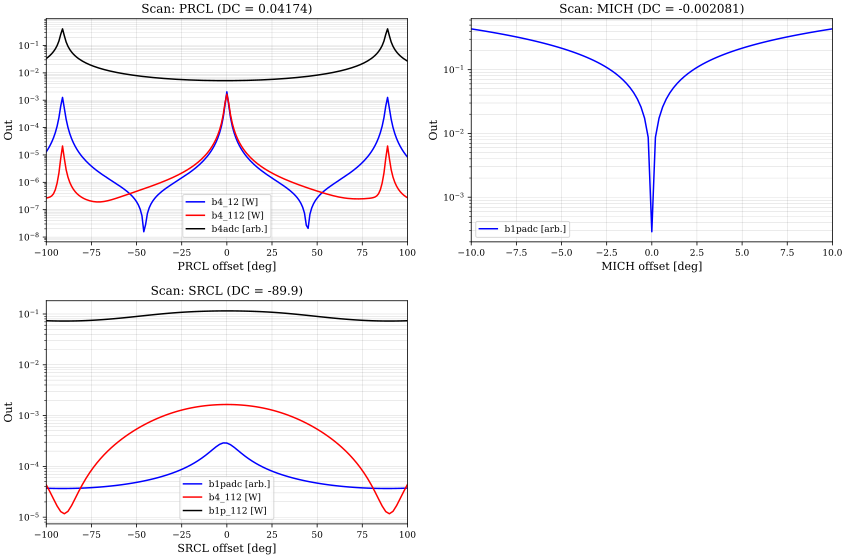

In [14]:
# dof scans and figures of merit using ifotools' plot_dof_scans.
citf_scans = citf_wp.deepcopy()
citf_scans.parse("ad b4adc B4_attenuator.p2.o f=l1.f n=0 m=0")

# Figures of merit (log scale)
plotting.plot_dof_scans(
    citf_scans,
    [
        ("PRCL", ["b4_12", "b4_112", "b4adc"], (-100, 100, 200)),
        ("MICH", "b1padc", (-10, 10, 100)),
        ("SRCL", ["b1padc", "b4_112", "b1p_112"], (-100, 100, 100)),
    ],
    logy=True,
    figsize=(12, 8),
)
plt.show()

# b4adc and b1padc is an amplitude detector for carrier frequency
# and others are rf detectors in the plot

Carrier is almost anti-resonant at the PRCL working point but the sidebands 6 and 56 MHz are both resonant in the PRC which should be the case for the working point. Now the PRCL working point is confirmed well with the figures of merit as shown above.

The MICH working point should satisfy only one condition that the carrier is on dark-fringe. The MICH dof does not get affected once the CARM-offset is reduced. It is independent of the CARM offset. 

The SRCL working point should satisfy the following conditions:
1. The 56 MHz sideband is resonant inside the PRC and SRC. 
2. The carrier is resonant inside the SRCL as after CARM-offset reduction the carrier becomes anti-resonant inside the SRC.

### Sensing Matrix & Optimization

Now we optimize the readouts for the 1f error signals which will be used for the initial lock of the CITF dofs.

In [15]:
# Sensing Matrix of our model
citf_tun = citf_wp.deepcopy()
important_dofs = ["MICH", "PRCL", "SRCL"]
readouts = ["B2_6", "B2_18", "B2_56", "B2_168"]

model_info.print_sensing_matrix(citf_tun, important_dofs, readouts)

┌──────╥────────┬─────────┬──────────┬──────────┬─────────┬─────────┬──────────┬──────────┐
│      ║ B2_6_I │ B2_6_Q  │ B2_18_I  │ B2_18_Q  │ B2_56_I │ B2_56_Q │ B2_168_I │ B2_168_Q │
╞══════╬════════╪═════════╪══════════╪══════════╪═════════╪═════════╪══════════╪══════════╡
│ MICH ║ -0.015 │    0.04 │ -4.1E-05 │ -0.00045 │    0.23 │   0.064 │   -0.001 │    0.002 │
├──────╫────────┼─────────┼──────────┼──────────┼─────────┼─────────┼──────────┼──────────┤
│ PRCL ║   -9.2 │     1.9 │    0.068 │   -0.034 │      -1 │     6.7 │   -0.053 │   -0.019 │
├──────╫────────┼─────────┼──────────┼──────────┼─────────┼─────────┼──────────┼──────────┤
│ SRCL ║ -0.002 │ 0.00046 │  4.2E-05 │ -2.6E-05 │  -0.019 │    0.12 │  -0.0015 │ -0.00057 │
└──────╨────────┴─────────┴──────────┴──────────┴─────────┴─────────┴──────────┴──────────┘



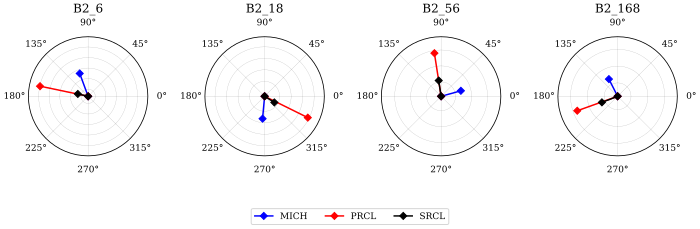

In [16]:
# Polar plots for the sensing matrix
sensing_matrix = citf_tun.run(SensingMatrixDC(important_dofs, readouts))
sm_fig, sm_axs = sensing_matrix.plot(1, 4, figsize=(10, 3.2))
sm_axs[-1].get_legend().remove()
sm_fig.legend(
    sm_axs[-1].lines,
    sensing_matrix.dofs,
    loc="lower center",
    ncols=len(sensing_matrix.dofs),
)
sm_fig.subplots_adjust(bottom=0.25);

In [17]:
model_info.print_sensing_matrix(
    citf_tun, important_dofs, readouts, frequency=20, scale=1e-6
)

Response at 20 Hz, values scaled by 1e-06:
┌──────╥──────────┬─────────┬─────────┬─────────┬──────────┬─────────┬──────────┬──────────┐
│      ║  B2_6_I  │ B2_6_Q  │ B2_18_I │ B2_18_Q │ B2_56_I  │ B2_56_Q │ B2_168_I │ B2_168_Q │
╞══════╬══════════╪═════════╪═════════╪═════════╪══════════╪═════════╪══════════╪══════════╡
│ MICH ║      1.1 │      12 │  -0.059 │   -0.13 │       79 │      18 │    -0.32 │     0.69 │
├──────╫──────────┼─────────┼─────────┼─────────┼──────────┼─────────┼──────────┼──────────┤
│ PRCL ║ -3.1E+03 │ 6.6E+02 │      23 │     -11 │ -3.5E+02 │ 2.3E+03 │      -18 │     -6.4 │
├──────╫──────────┼─────────┼─────────┼─────────┼──────────┼─────────┼──────────┼──────────┤
│ SRCL ║    -0.69 │    0.16 │   0.014 │  -0.009 │     -6.3 │      42 │     -0.5 │    -0.19 │
└──────╨──────────┴─────────┴─────────┴─────────┴──────────┴─────────┴──────────┴──────────┘



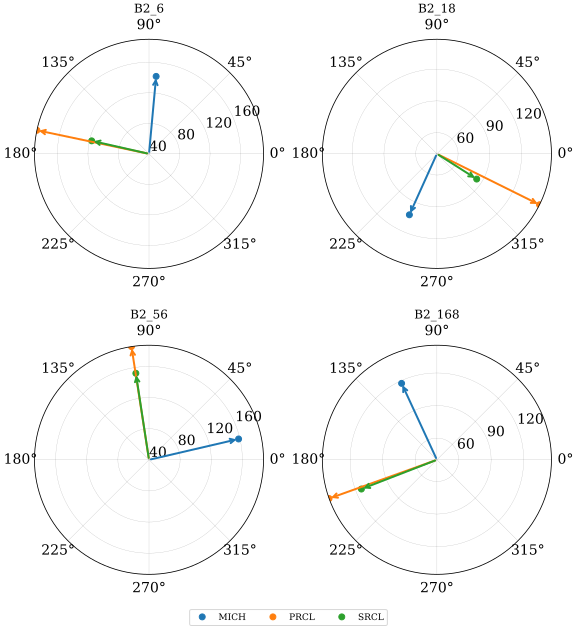

In [18]:
plotting.plot_sensing_matrix(
    citf_tun, important_dofs, readouts, frequency=20, min_gain=40
);

# the sensing matrix here can also be output at a particular frequency (20 Hz here) and also with a minimum gain

In [19]:
# Finalizing dof and its error signals
# Not optimizing for the SRCL as MICH and SRCL have the same readout 
# just different quadratures
dof_pds = {"PRCL": "B2_6_I", "MICH": "B2_56_I"}  # , 'SRCL': 'B2_56_Q'}

## Optimizing the demodulation phases for the chosen error signals (1f)
## dof_pds is the chosen error signals for the locks
for dof, pd in dof_pds.items():
    citf_tun.run(OptimiseRFReadoutPhaseDC(dof, pd))

print(f"Demodulation phase:{citf_tun.B2_6.phase.eval()} deg")
print(f"Demodulation phase:{citf_tun.B2_56.phase.eval()} deg")

Demodulation phase:168.1225224737602 deg
Demodulation phase:15.568303179830234 deg


### Locking (1f): 

Here we perform the initial lock of the CITF using 1f signals. Later we will lock the same dofs using 3f signals which are used in the experiment during the CARM-offset reduction.

In [20]:
## CITF Locking scheme
citf_lock = citf_tun.deepcopy()

# Defining the locks in our model
# for the CITF lock acquisition (1f signals)
citf_lock.parse(
    """  
    # locks
    lock PRCL_lock B2_6.outputs.I PRCL.DC 0 1e-14
    lock MICH_lock B2_56.outputs.I MICH.DC 0 1e-14
    lock SRCL_lock B2_56.outputs.Q SRCL.DC 0 1e-14  
    """
)

model_info.print_sensing_matrix(citf_lock, important_dofs, readouts)

┌──────╥────────┬──────────┬──────────┬──────────┬─────────┬─────────┬──────────┬──────────┐
│      ║ B2_6_I │  B2_6_Q  │ B2_18_I  │ B2_18_Q  │ B2_56_I │ B2_56_Q │ B2_168_I │ B2_168_Q │
╞══════╬════════╪══════════╪══════════╪══════════╪═════════╪═════════╪══════════╪══════════╡
│ MICH ║  0.023 │   -0.036 │ -4.1E-05 │ -0.00045 │    0.24 │ 1.6E-05 │   -0.001 │    0.002 │
├──────╫────────┼──────────┼──────────┼──────────┼─────────┼─────────┼──────────┼──────────┤
│ PRCL ║    9.4 │ -0.00017 │    0.068 │   -0.034 │     0.8 │     6.8 │   -0.053 │   -0.019 │
├──────╫────────┼──────────┼──────────┼──────────┼─────────┼─────────┼──────────┼──────────┤
│ SRCL ║ 0.0021 │ -3.3E-05 │  4.2E-05 │ -2.6E-05 │   0.015 │    0.12 │  -0.0015 │ -0.00057 │
└──────╨────────┴──────────┴──────────┴──────────┴─────────┴─────────┴──────────┴──────────┘



In [ ]:
# error signals for the 1f locks
plotting.plot_error_signals(citf_lock, plot_both_quadratures=True);

In [ ]:
# set lock gains before running locks
citf_lock.run(SetLockGains(verbose=True));

In [ ]:
# Checking the error signals before locking
errs_sig = citf_lock.run(GetErrorSignals("MICH_lock", "PRCL_lock", "SRCL_lock"))
print("Initial Error Signals:", errs_sig.results, end="\n\n")

In [ ]:
# Running the locks
citf_lock.run(RunLocks(method="newton", display_progress=True, show_progress_bar=True))

In [ ]:
# tunings of the dof after pretunings
model_info.print_dofs(citf_lock, important_dofs)

In [ ]:
model_info.print_tunings(citf_lock, only_dof=True)

In [ ]:
model_info.print_lock_status(citf_lock)

In [ ]:
model_info_virgo.print_powers(citf_lock)

### Locking the CITF using 3f

In [ ]:
# Locking the CITF with the 3f signals
citf_3f = citf_wp.deepcopy()

# Finalizing dof and its error signals
dof_pds = {"PRCL": "B2_18_I", "MICH": "B2_168_I"}  # , 'SRCL': 'B2_56_Q'}

## Optimizing the demodulation phases for the chosen error signals
## dof_pds is the chosen error signals for the locks
for dof, pd in dof_pds.items():
    citf_3f.run(OptimiseRFReadoutPhaseDC(dof, pd))

print(f"Demodulation phase:{citf_3f.B2_18.phase.eval()} deg")
print(f"Demodulation phase:{citf_3f.B2_168.phase.eval()} deg")

In [ ]:
## CITF Locking scheme
citf_3f.parse(
    """  
    # locks
    lock PRCL_3f B2_18.outputs.I PRCL.DC 0 1e-14
    lock MICH_3f B2_168.outputs.I MICH.DC 0 1e-14
    lock SRCL_3f B2_168.outputs.Q SRCL.DC 0 1e-14 
    """
)

# setting the right gains of the locks
citf_3f.run(SetLockGains())

In [ ]:
model_info.print_sensing_matrix(citf_3f, important_dofs, readouts, frequency=20, scale=1e-6)

In [ ]:
# Locking the dofs with their respective sensors
# Few checks before running the locks
errs_sig = citf_3f.run(GetErrorSignals("MICH_3f", "PRCL_3f", "SRCL_3f"))
print("Initial Error Signals:", errs_sig.results, end="\n\n")

In [ ]:
# Running the locks
citf_3f.run(RunLocks(method="newton", display_progress=True, show_progress_bar=True))

In [ ]:
plotting.plot_error_signals(citf_3f, plot_both_quadratures=True);

In [ ]:
model_info.print_tunings(citf_3f, only_dof=True)

In [ ]:
model_info.print_lock_status(citf_3f)

In [ ]:
model_info_virgo.print_powers(citf_3f)

## 5. CARM-offset Reduction

In [ ]:
## Copying the model
citf_cor = citf_3f.deepcopy()

# Removing the CARM offset to bring the arms back to resonance
# for the main laser (IR) beam
# Quick check on the state and tunings of the model
model_info_virgo.print_model_state(citf_cor);

In [ ]:
model_info.print_tunings(citf_cor, only_dof=True)

In [ ]:
# should be locked (the error signal should be 0)
errs_sig = citf_cor.run(GetErrorSignals("MICH_3f", "PRCL_3f", "SRCL_3f"))
print(f"Error signals after removing CARM offset: {errs_sig.results}")

In [ ]:
# CARM offset reduction. This offset was added to the
# individual mirror dofs. Now after tuning the IFO to the right OP
# we can remove the CARM offset and lock the CARM and DARM dofs.
citf_cor.NE_z.DC -= 10.8
citf_cor.WE_z.DC -= 10.8
citf_cor.run()

# checking the error signals before removing the CARM offset
errs_sig = citf_cor.run(GetErrorSignals("MICH_3f", "PRCL_3f", "SRCL_3f"))
print(f"Error signals after removing CARM offset: {errs_sig.results}")

In [ ]:
# The error signals have moved, now RunLocks again on 3f
# Running the locks
citf_cor.run(RunLocks(method="newton", display_progress=True, show_progress_bar=True))

In [ ]:
model_info_virgo.print_powers(citf_cor)

In [ ]:
model_info.print_tunings(citf_cor, only_dof=True)

## 6. Low Noise State

Where all the controls are handed off to 1f signals along with CARM and DARM. At this point all the dofs should be at the right operating point. 

In [ ]:
# Low Noise (State)
# Carm null 1f locks 
ifo_cd = citf_cor.deepcopy()
all_dofs = ["PRCL", "MICH", "SRCL", "CARM", "DARM"]
all_readouts = ["B2_8", "B4_6", "B2_56", "B1p_56"]

# Turning on the 8 MHz modulators
ifo_cd.eom8.midx = advi.eom8.midx
ifo_cd.run()

# Removing the previous locks
ifo_cd.remove("MICH_3f")
ifo_cd.remove("PRCL_3f")
ifo_cd.remove("SRCL_3f")

# Adding new locks
ifo_cd.parse(
    """  
    # locks
    lock PRCL_lock B2_8.outputs.I PRCL.DC 0 1e-14
    lock MICH_lock B2_56.outputs.I MICH.DC 0 1e-14
    lock SRCL_lock B2_56.outputs.Q SRCL.DC 0 1e-14 
    lock CARM_lock B4_6.outputs.I CARM.DC 0 1e-14
    lock DARM_lock B1p_56.outputs.I DARM.DC 0 1e-14
    """
)

model_info_virgo.print_model_state(ifo_cd, verbose=True);


In [ ]:
# Printing the sensing matrix
model_info.print_sensing_matrix(ifo_cd, all_dofs, all_readouts, frequency=20)

In [ ]:
# Polar plots for the sensing matrix
sensing_matrix2 = ifo_cd.run(SensingMatrixDC(all_dofs, all_readouts))
sm_fig, sm_axs = sensing_matrix2.plot(1, 4, figsize=(10, 3.2))
sm_axs[-1].get_legend().remove()
sm_fig.legend(
    sm_axs[-1].lines,
    sensing_matrix2.dofs,
    loc="lower center",
    ncols=len(sensing_matrix2.dofs),
)
sm_fig.subplots_adjust(bottom=0.25);

In [ ]:
plotting.plot_error_signals(ifo_cd, plot_both_quadratures=True);

In [ ]:
## Optimizing the demodulation phases for the chosen error signals
## dof_pds is the chosen error signals for the locks
dof_pds = {
    "PRCL": "B2_8_I",
    "MICH": "B2_56_I",
    "SRCL": "B2_56_Q",
    "CARM": "B4_6_I",
    "DARM": "B1p_56_I",
}

for dof, pd in dof_pds.items():
    ifo_cd.run(OptimiseRFReadoutPhaseDC(dof, pd))

In [ ]:
plotting.plot_error_signals(ifo_cd, plot_both_quadratures=True);

In [ ]:
# Locking the interferometer
ifo = ifo_cd.deepcopy()
model_info_virgo.print_model_state(ifo, verbose=True);

In [ ]:
# Setting gains for the locks
ifo.run(SetLockGains())

# Locking the dofs with their respective sensors
errs_sig = ifo.run(
    GetErrorSignals("PRCL_lock", "MICH_lock", "SRCL_lock", "CARM_lock", "DARM_lock")
)

print("Initial Error Signals:", errs_sig.results, end="\n\n")

In [ ]:
# Running the locks
ifo.run(RunLocks(method="newton", display_progress=True, show_progress_bar=True))

In [ ]:
model_info.print_dofs(ifo, dofs=all_dofs)

In [ ]:
model_info.print_lock_status(ifo)

In [ ]:
model_info_virgo.print_powers(ifo)